In [3]:
import ultralytics, PIL
print("ultralytics:", ultralytics.__version__)
print("pillow:", PIL.__version__)
ultralytics.checks()

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7108.1/8156.9 GB disk)


In [4]:
!pip install -q ultralytics roboflow
import os
os.environ["WANDB_DISABLED"] = "true"

In [5]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="wMcVBp1WR0sSDEIryYDP")
project = rf.workspace("abhi-jeet").project("fort_object_detection")
version = project.version(1)
dataset = version.download("yolov11")
                

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fort_object_detection-1 in yolov11:: 100%|██████████| 669/669 [00:00<00:00, 8758.29it/s]


In [9]:
import os, glob, yaml

DATA_DIR = "/kaggle/working/fort_object_detection-1"
yaml_path = f"{DATA_DIR}/data.yaml"

cfg = yaml.safe_load(open(yaml_path))
cfg["path"] = DATA_DIR
cfg["train"] = "train/images"
cfg["val"] = "valid/images"
if os.path.exists(f"{DATA_DIR}/test/images"):
    cfg["test"] = "test/images"
else:
    cfg.pop("test", None)
yaml.dump(cfg, open(yaml_path, "w"))
print(cfg)   # expect nc: 1 and names: ['gateway']

for s in ["train", "valid", "test"]:
    imgs = glob.glob(f"{DATA_DIR}/{s}/images/*")
    labels = glob.glob(f"{DATA_DIR}/{s}/labels/*.txt")
    empty = sum(1 for l in labels if os.path.getsize(l) == 0)
    print(s, len(imgs), "images,", empty, "background (empty label)")

{'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 2, 'names': ['Gateway', 'gate'], 'roboflow': {'workspace': 'abhi-jeet', 'project': 'fort_object_detection', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/abhi-jeet/fort_object_detection/dataset/1'}, 'path': '/kaggle/working/fort_object_detection-1'}
train 291 images, 0 background (empty label)
valid 27 images, 0 background (empty label)
test 14 images, 0 background (empty label)


In [10]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")
model.train(
    data=yaml_path,
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
    seed=42,
    device=0,
    workers=2,
    project="/kaggle/working/runs",
    name="gateway_only_v1",
)

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/fort_object_detection-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=gateway_only_v1, nbs=64, nms=None, ops

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


      2/100      4.49G      1.716      2.198      1.903          5        640: 100% ━━━━━━━━━━━━ 19/19 5.8it/s 3.3s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.8it/s 0.4s
                   all         27         27      0.575      0.192      0.044     0.0153

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100       4.5G      1.745      2.142      1.922          9        640: 100% ━━━━━━━━━━━━ 19/19 5.9it/s 3.2s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.1it/s 0.3s
                   all         27         27    0.00621      0.135    0.00396   0.000886

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100       4.5G      1.863      2.129      1.985          6        640: 100% ━━━━━━━━━━━━ 19/19 6.0it/s 3.2s0.3s
                 Class     Images  Instances      Box(

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e90906730e0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

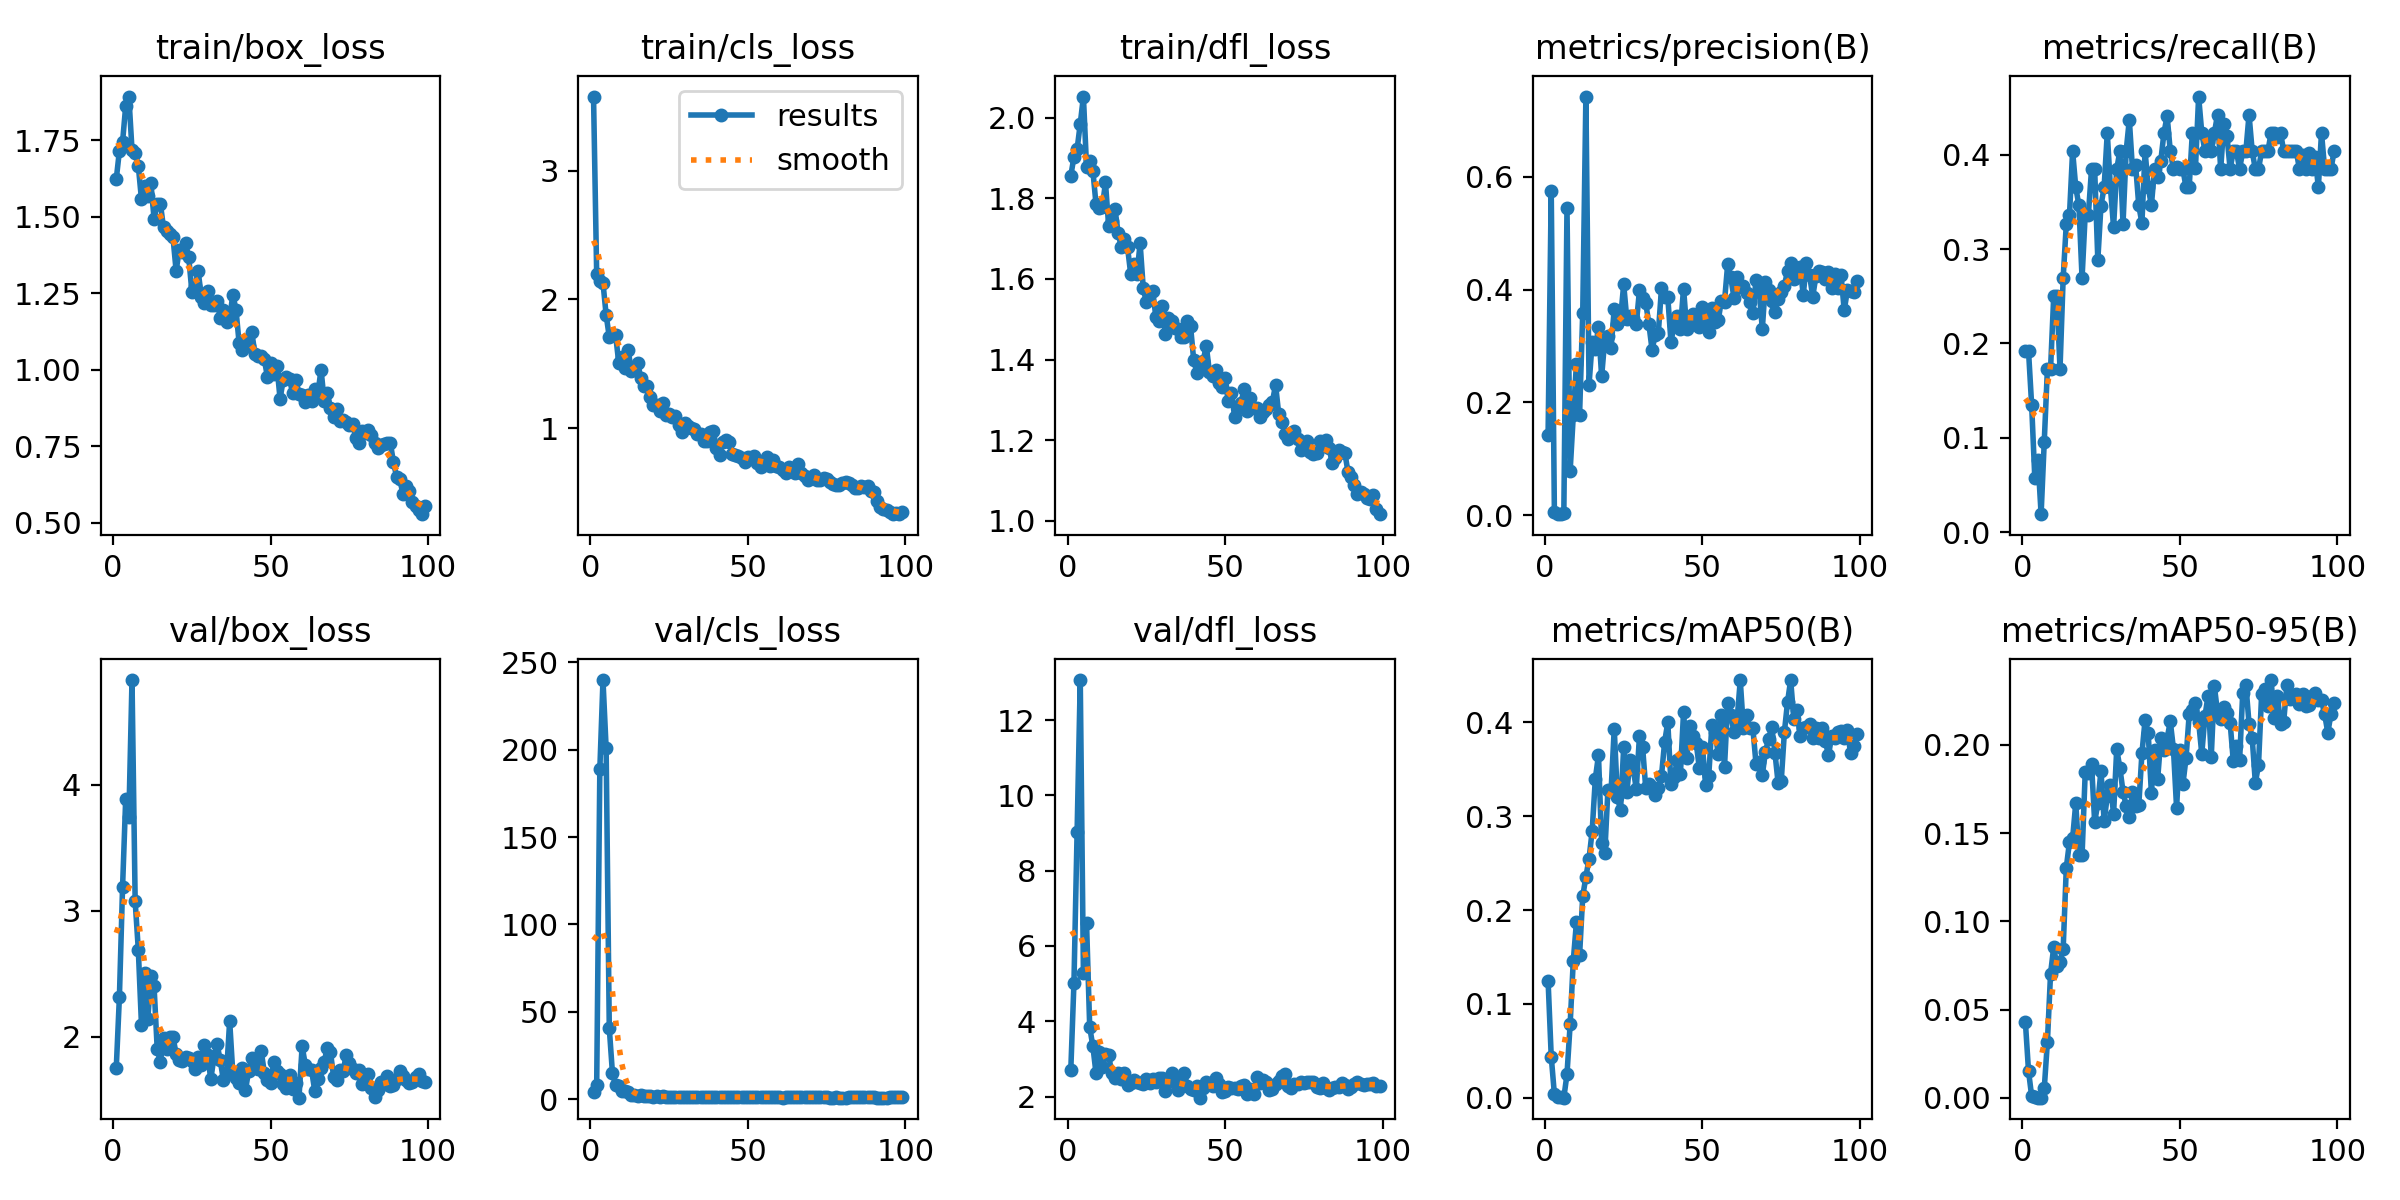

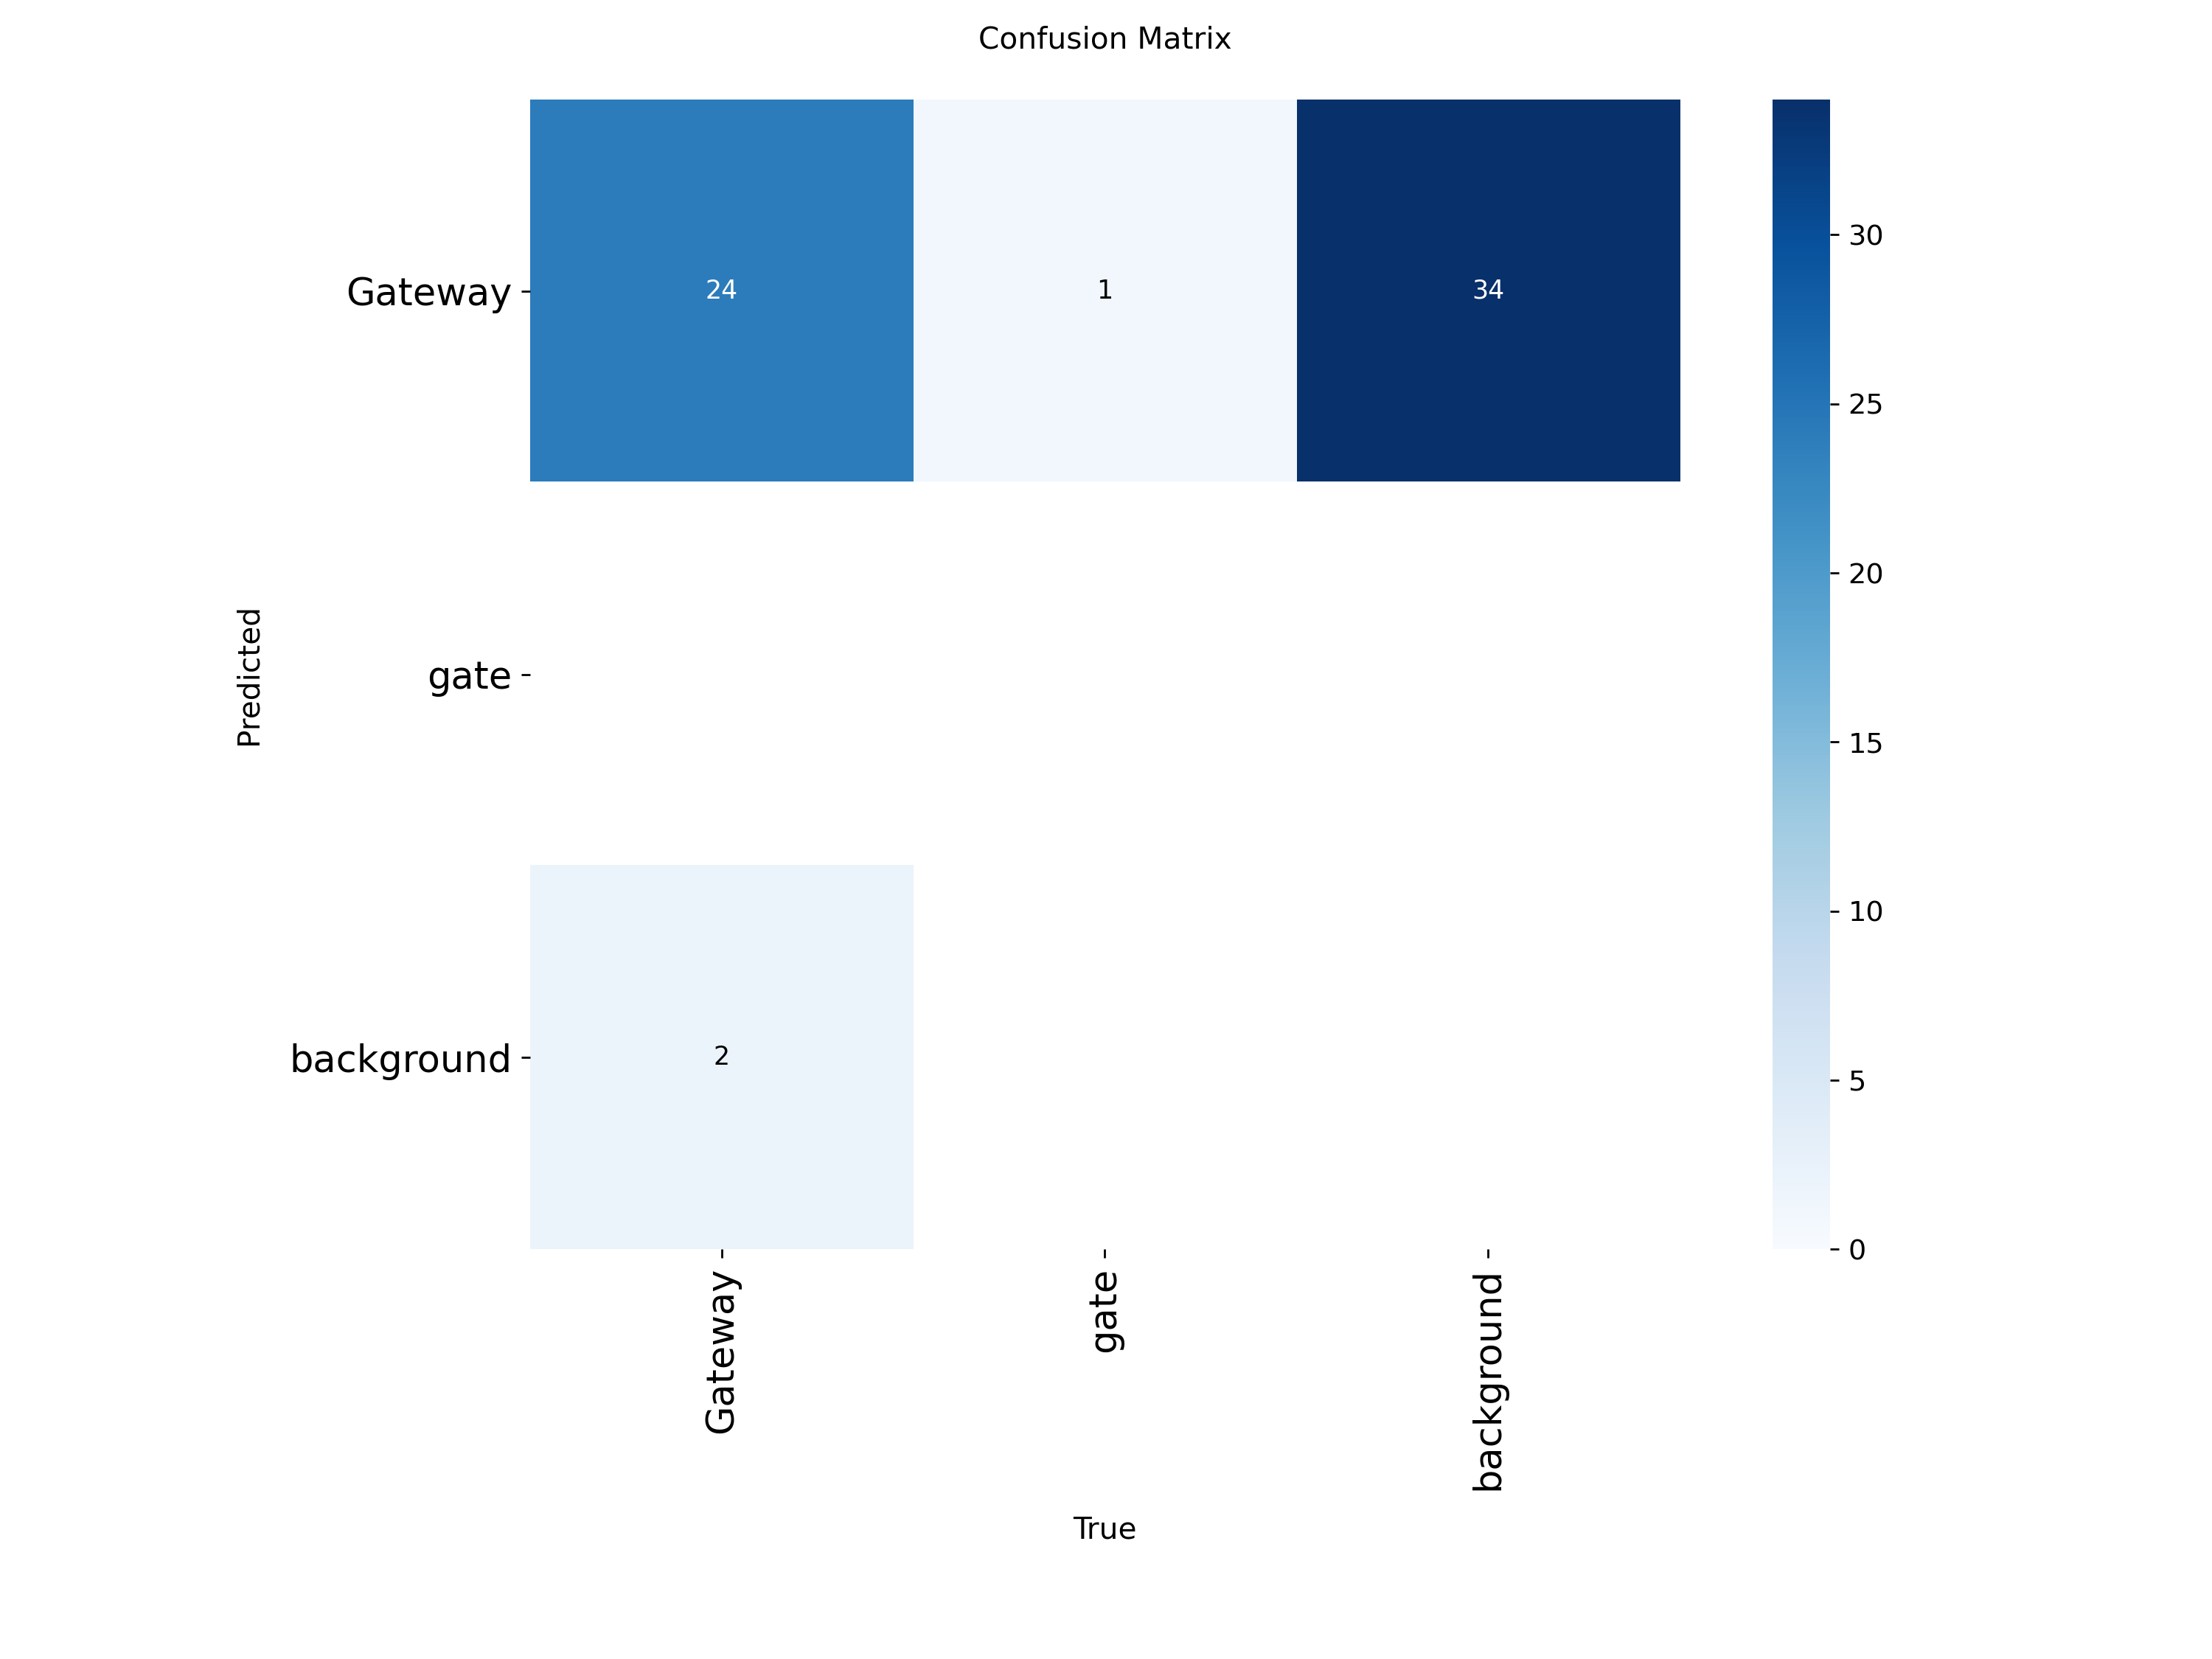

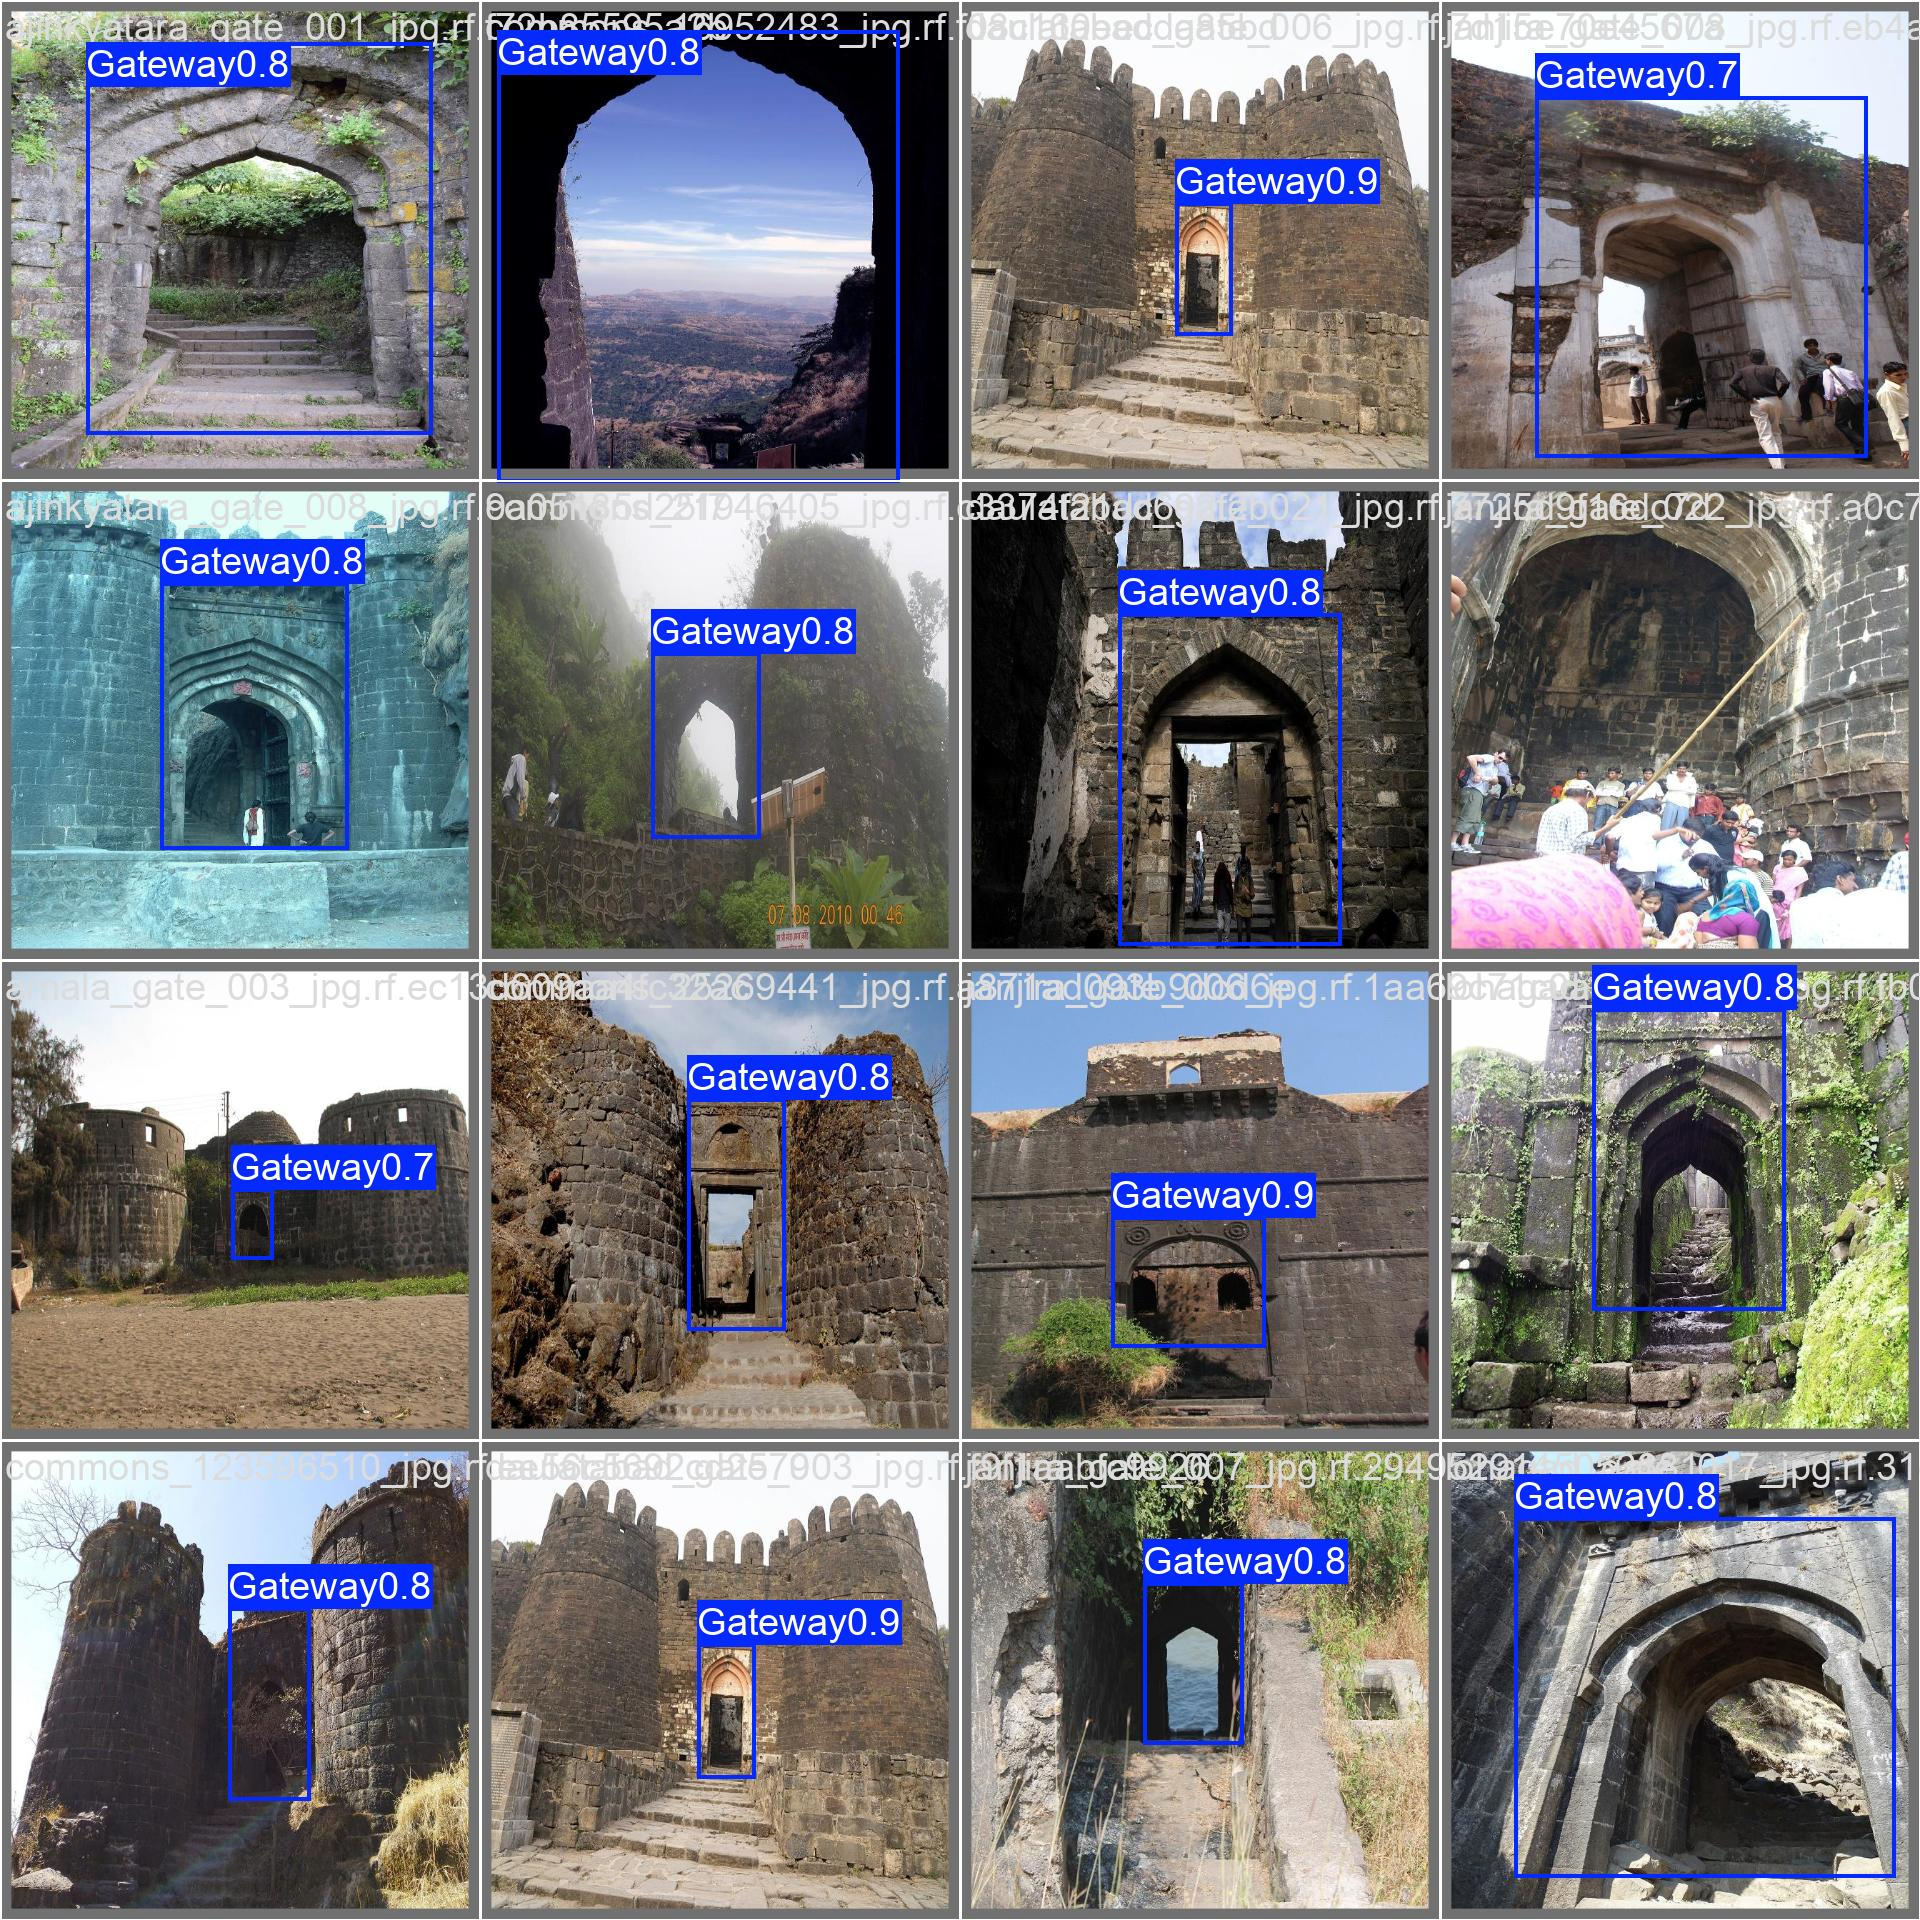

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1600.2±413.6 MB/s, size: 71.7 KB)
val: Scanning /kaggle/working/fort_object_detection-1/test/labels... 14 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 1.1Kit/s 0.0s
val: New cache created: /kaggle/working/fort_object_detection-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.0it/s 0.3s
                   all         14         14      0.908      0.709      0.866      0.518
               Gateway         14         14      0.908      0.709      0.866      0.518
Speed: 0.4ms preprocess, 11.8ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
Split: test
Precision: 0.908
Recall:    0.709
mAP50:     0.866
mAP50-95:  0.518


In [11]:
from IPython.display import Image, display
run = "/kaggle/working/runs/gateway_only_v1"
for f in ["results.png", "PR_curve.png", "F1_curve.png", "confusion_matrix.png", "val_batch0_pred.jpg"]:
    if os.path.exists(f"{run}/{f}"):
        display(Image(f"{run}/{f}"))

best = YOLO(f"{run}/weights/best.pt")
split = "test" if "test" in cfg else "val"
m = best.val(data=yaml_path, split=split)
print("Split:", split)
print("Precision:", round(m.box.mp, 3))
print("Recall:   ", round(m.box.mr, 3))
print("mAP50:    ", round(m.box.map50, 3))
print("mAP50-95: ", round(m.box.map, 3))


0: 640x640 1 Gateway, 10.0ms
1: 640x640 1 Gateway, 10.0ms
2: 640x640 (no detections), 10.0ms
3: 640x640 1 Gateway, 10.0ms
4: 640x640 1 Gateway, 10.0ms
5: 640x640 (no detections), 10.0ms
6: 640x640 1 Gateway, 10.0ms
7: 640x640 1 Gateway, 10.0ms
Speed: 0.9ms preprocess, 10.0ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/preds
janjira_gate_012_jpg.rf.874bc50325ce98b3be3b3939a10dc3a9.jpg [0.36]
torna_gate_001_jpg.rf.4bbc67dc3a28c19771a002ca5d1623f0.jpg [0.79]
janjira_gate_001_jpg.rf.3a6d7907883d27b874c71e417fdb6792.jpg []
vasai_gate_004_jpg.rf.fcd3847d95d9c3e6de4ce6f1f404de20.jpg [0.71]
sinhgad01_jpg.rf.4edff754e345c331705297ea9a44561e.jpg [0.84]
shivneri_gate_002_jpg.rf.015ff19eeba98c63afb367c3a731d9cd.jpg []
commons_21948216_jpg.rf.4dacf630708a8ab05cfd59dd9fe1d0e5.jpg [0.82]
panhala_gate_012_jpg.rf.0a1aea741d664ce8630f6be8f6392261.jpg [0.79]


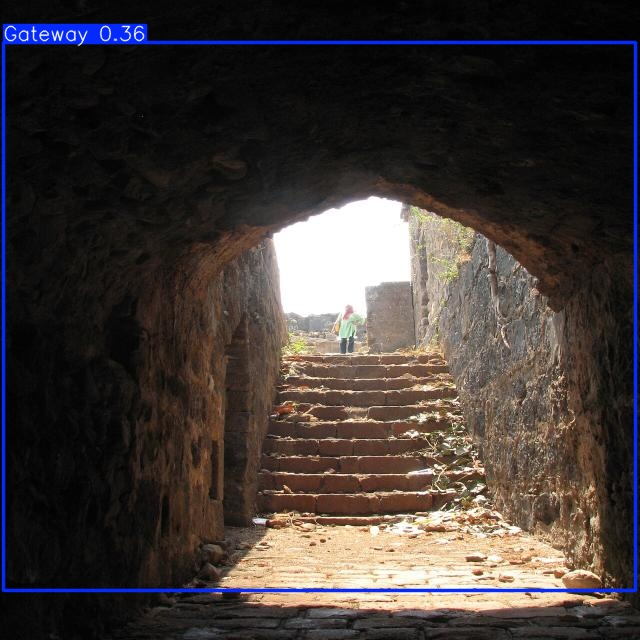

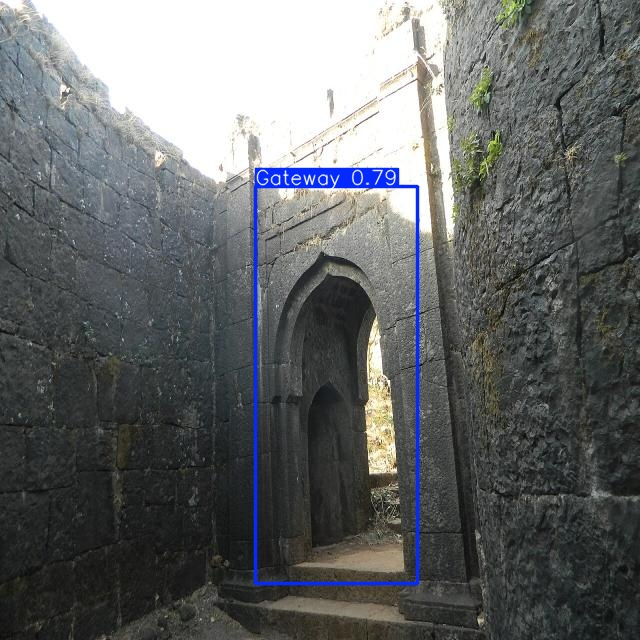

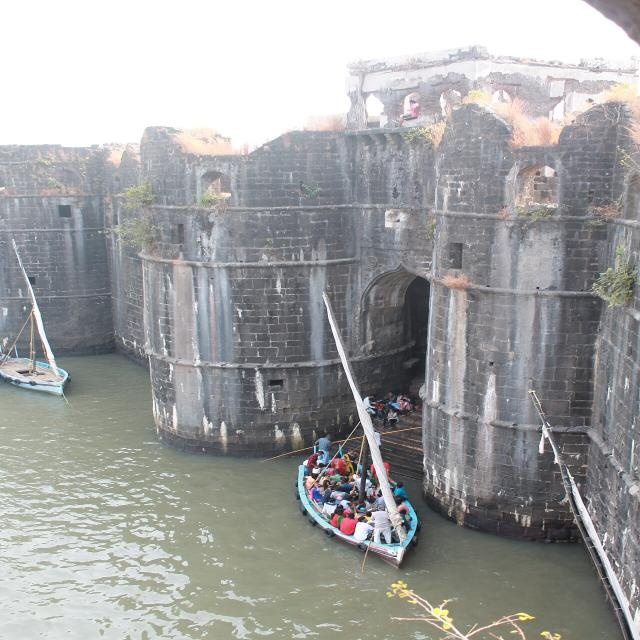

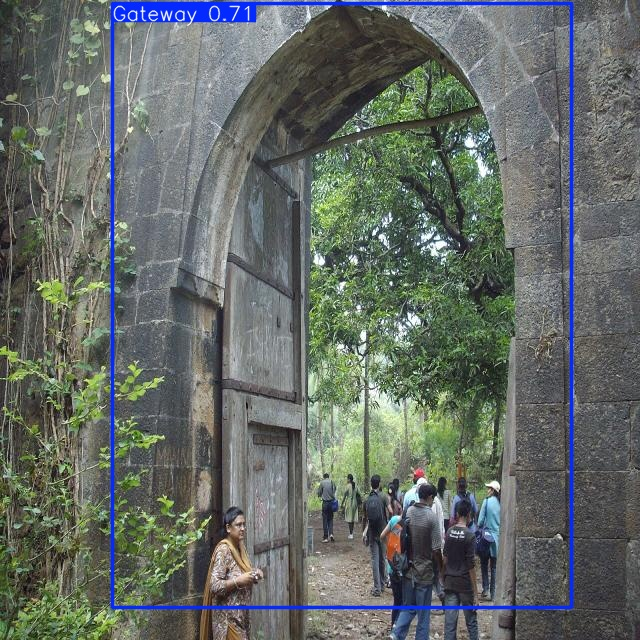

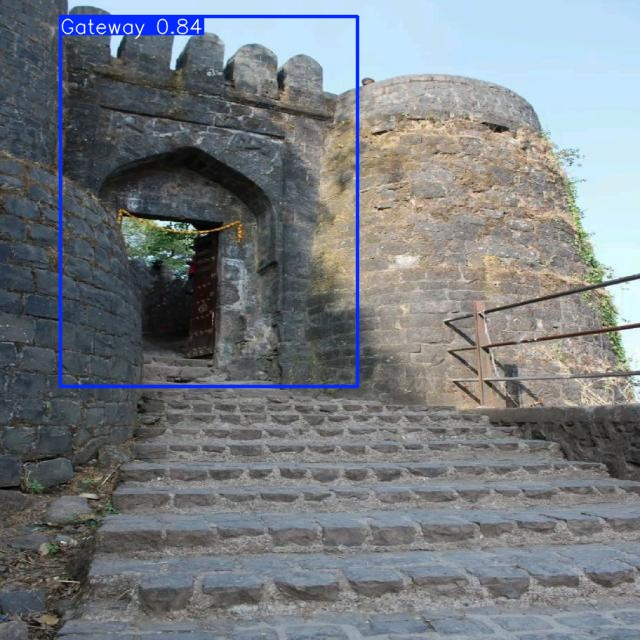

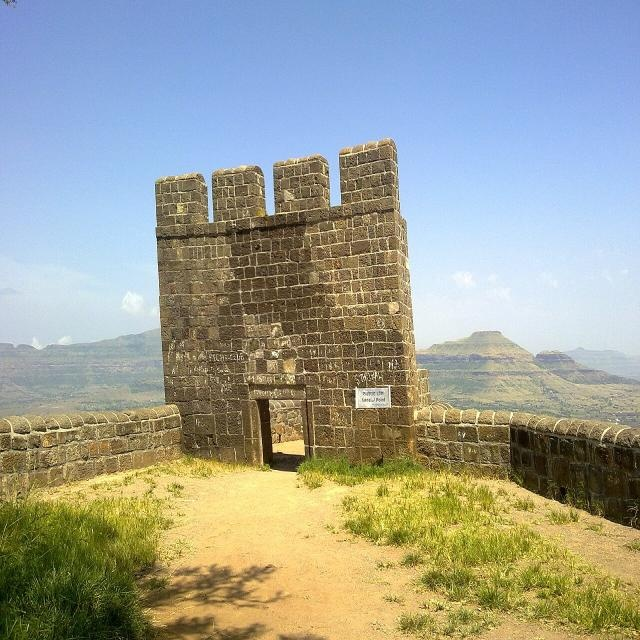

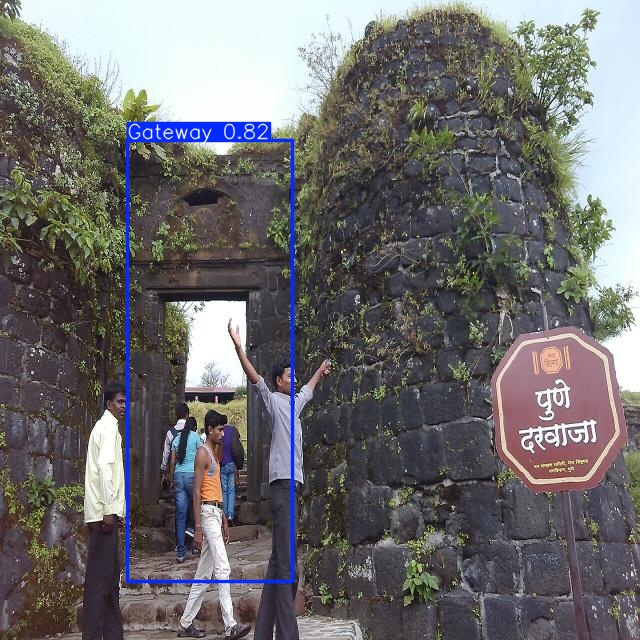

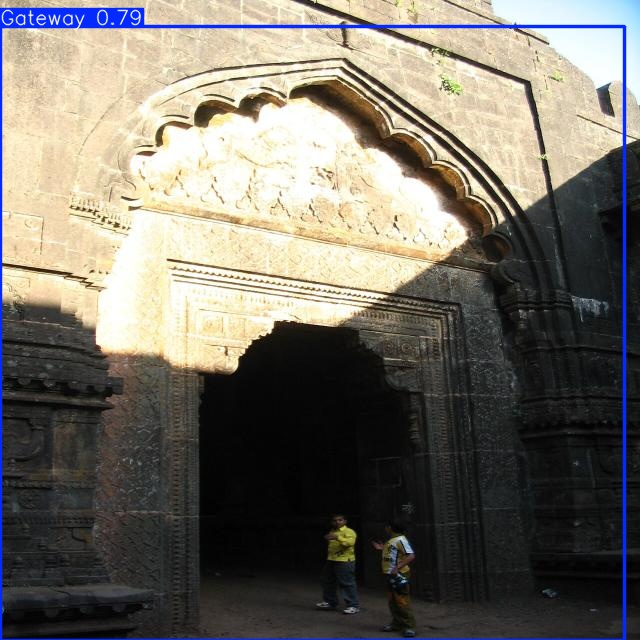

In [12]:
imgs = glob.glob(f"{DATA_DIR}/test/images/*")[:8]
preds = best.predict(imgs, conf=0.25, save=True,
                     project="/kaggle/working/runs", name="preds", exist_ok=True)
for r in preds:
    print(os.path.basename(r.path), [round(float(c), 2) for c in r.boxes.conf])

for p in glob.glob("/kaggle/working/runs/preds/*.jpg")[:8]:
    display(Image(p))

In [13]:
import shutil
shutil.copy(f"{run}/weights/best.pt", "/kaggle/working/gateway_best.pt")

'/kaggle/working/gateway_best.pt'


0: 640x640 1 Gateway, 11.6ms
1: 640x640 1 Gateway, 11.6ms
2: 640x640 (no detections), 11.6ms
3: 640x640 1 Gateway, 11.6ms
4: 640x640 1 Gateway, 11.6ms
5: 640x640 (no detections), 11.6ms
6: 640x640 1 Gateway, 11.6ms
7: 640x640 1 Gateway, 11.6ms
Speed: 1.0ms preprocess, 11.6ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/preds
janjira_gate_012_jpg.rf.874bc50325ce98b3be3b3939a10dc3a9.jpg [0.36]
torna_gate_001_jpg.rf.4bbc67dc3a28c19771a002ca5d1623f0.jpg [0.79]
janjira_gate_001_jpg.rf.3a6d7907883d27b874c71e417fdb6792.jpg []
vasai_gate_004_jpg.rf.fcd3847d95d9c3e6de4ce6f1f404de20.jpg [0.71]
sinhgad01_jpg.rf.4edff754e345c331705297ea9a44561e.jpg [0.84]
shivneri_gate_002_jpg.rf.015ff19eeba98c63afb367c3a731d9cd.jpg []
commons_21948216_jpg.rf.4dacf630708a8ab05cfd59dd9fe1d0e5.jpg [0.82]
panhala_gate_012_jpg.rf.0a1aea741d664ce8630f6be8f6392261.jpg [0.79]


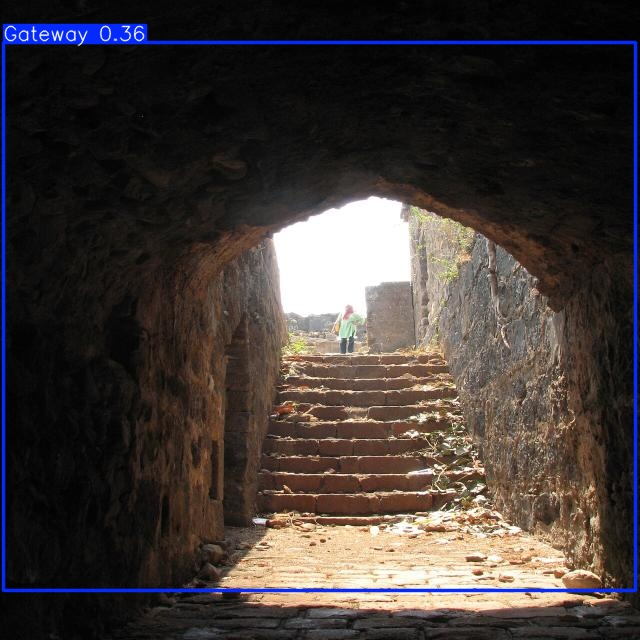

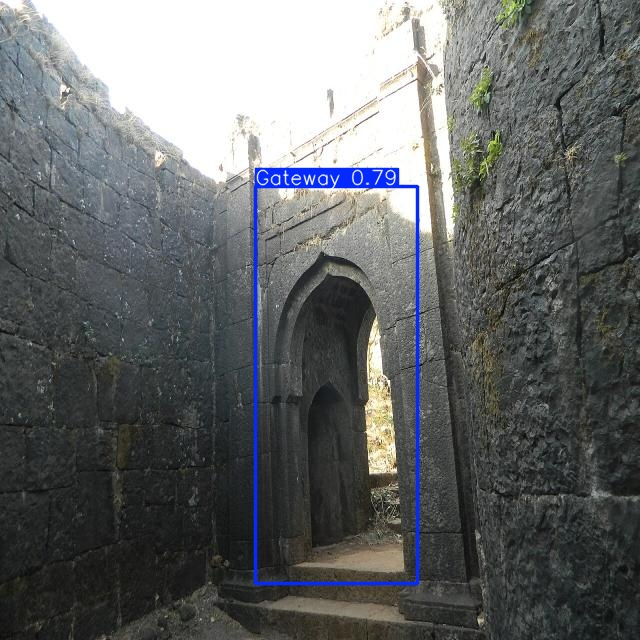

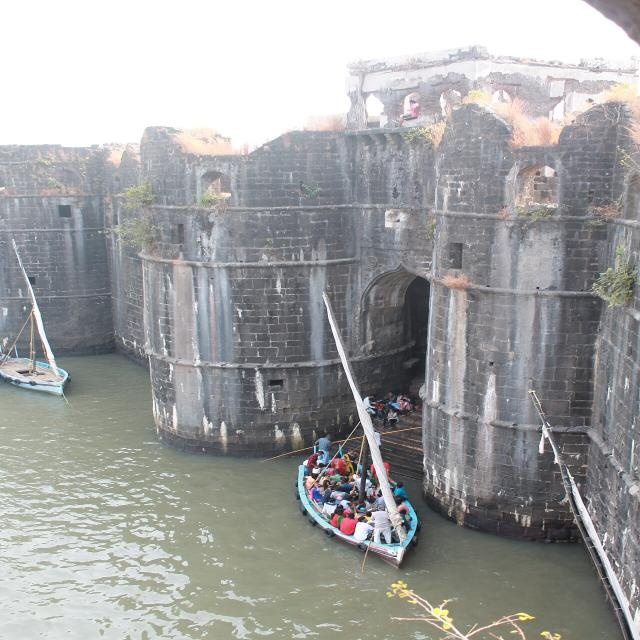

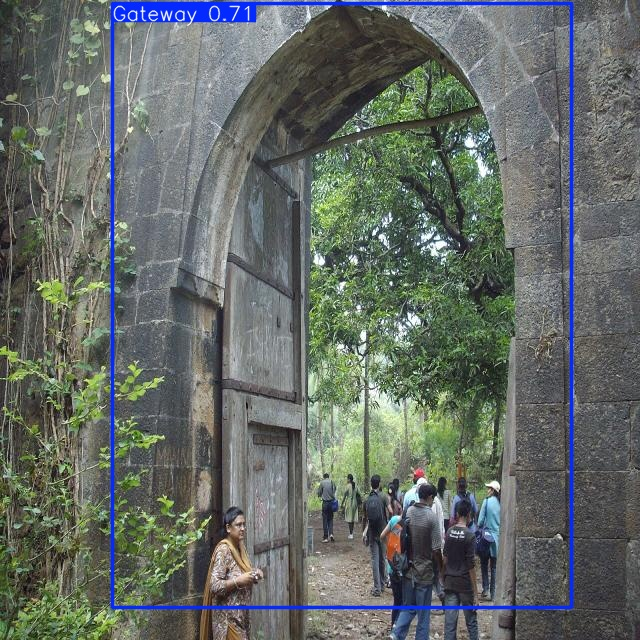

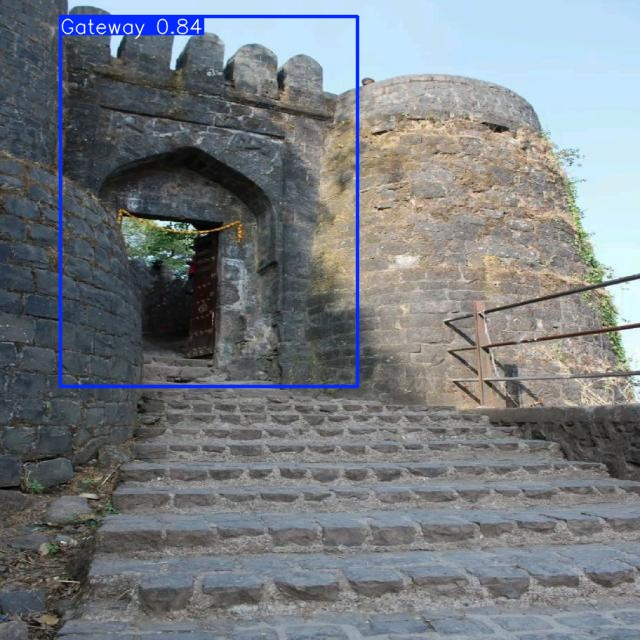

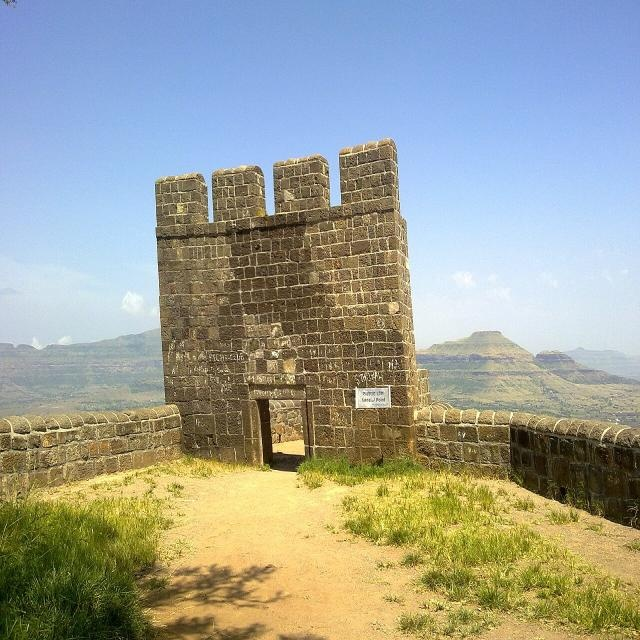

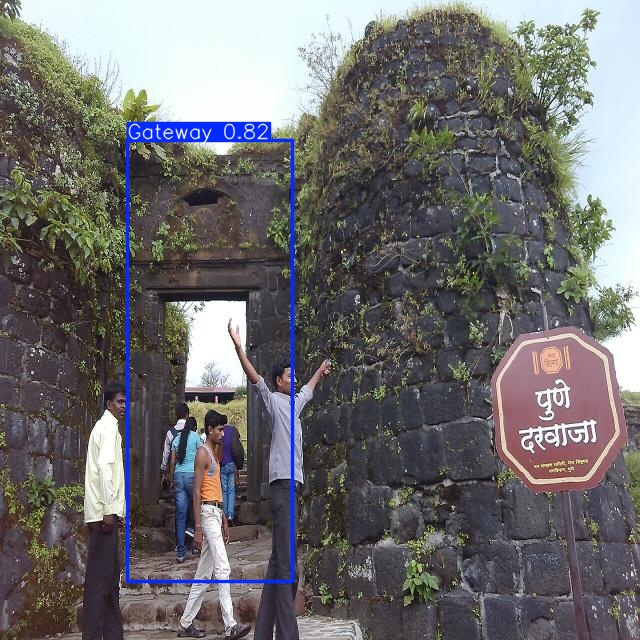

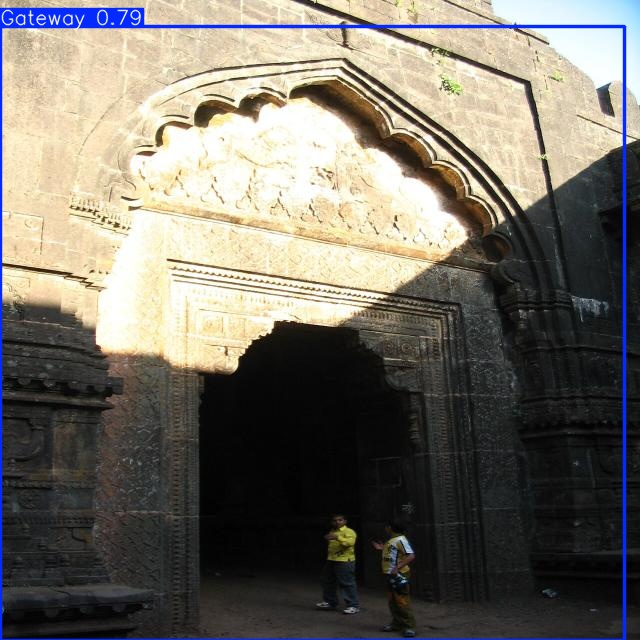

In [14]:
import glob
DATA_DIR = "/kaggle/working/fort_object_detection-1"
imgs = glob.glob(f"{DATA_DIR}/test/images/*")[:8]
preds = best.predict(imgs, conf=0.25, save=True,
                     project="/kaggle/working/runs", name="preds", exist_ok=True)
for r in preds:
    print(os.path.basename(r.path), [round(float(c), 2) for c in r.boxes.conf])

for p in glob.glob("/kaggle/working/runs/preds/*.jpg")[:8]:
    display(Image(p))

In [25]:
import io
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from PIL import Image as PILImage, ImageOps
from ultralytics import YOLO

MODEL_PATH = "/kaggle/working/runs/gateway_only_v1/weights/best.pt"   # or /kaggle/working/gateway_best.pt
CONF = 0.25                                                           # fixed, user cannot change it
model = YOLO(MODEL_PATH)

uploader = widgets.FileUpload(accept="image/*", multiple=False, description="Upload photo")
out = widgets.Output()

def get_file(up):
    v = up.value
    item = list(v.values())[0] if isinstance(v, dict) else (v[0] if len(v) else None)
    if item is None:
        return None, None
    if isinstance(item, dict):
        return item["name"], bytes(item["content"])
    return item.name, bytes(item.content)

def on_upload(change):
    with out:
        clear_output()
        name, content = get_file(uploader)
        if content is None:
            return
        img = ImageOps.exif_transpose(PILImage.open(io.BytesIO(content))).convert("RGB")
        r = model.predict(img, conf=CONF, verbose=False)[0]

        if len(r.boxes) == 0:
            print("No gateway detected")
        else:
            for b in r.boxes:
                print(f"{model.names[int(b.cls)]}  confidence = {float(b.conf):.2f}")

        plt.figure(figsize=(8, 6))
        plt.imshow(r.plot()[:, :, ::-1])
        plt.axis("off")
        plt.title(name)
        plt.show()

uploader.observe(on_upload, names="value")
display(uploader, out)

FileUpload(value=(), accept='image/*', description='Upload photo')

Output()